# Чтение Данных

Данные: 48 городов, 1991 год.

- City (Город): Название города

- Работа (Work): Взвешенное среднее числа рабочих часов, сосчитанное по 12
профессиям

- Цена (Price): Индекс цен 112 товаров и услуг, включая арендную плату за
жилье(значение для Цюриха взято за 100%)

- Заработная плата (Salary): Индекс заработной платы за час работы,
сосчитанный по 12 профессиям после налогов и вычетов (значение для Цюриха
взято за 100%)

In [1]:
# Библиотеки + Читаем файл

%pip -q install gdown

import gdown
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

file_id = "1tzLHiEN1BqvjlJaeQToBn0F69n-OQ-0W"


gdown.download(id=file_id, output="Econom_Cities_data.csv", quiet=False)

df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";")

Downloading...
From: https://drive.google.com/uc?id=1tzLHiEN1BqvjlJaeQToBn0F69n-OQ-0W
To: /content/Econom_Cities_data.csv
100%|██████████| 1.18k/1.18k [00:00<00:00, 2.36MB/s]


# Предварительный анализ

## Работа с типами данных и пропусками

In [2]:
df_raw # посмотрим на данные

,City,Work,Price,Salary
0,Amsterdam,1714,"65,6",49
1,Athens,1792,"53,8","30,4"
2,Bogota,2152,"37,9","11,5"
3,Bombay,2052,"30,3","5,3"
4,Brussels,1708,"73,8","50,5"
5,Buenos_Aires,1971,"56,1","12,5"
6,Cairo,-9999,"37,1",-9999
7,Caracas,2041,61,"10,9"
8,Chicago,1924,"73,9","61,9"
9,Copenhagen,1717,"91,3","62,9"


In [3]:
df_raw.dtypes # проблема Price и Salary имеют тип object

,0
City,object
Work,int64
Price,object
Salary,object


In [4]:
# приведем переменные к числовым значениям
cols = ['Work', 'Price', 'Salary']

for col in cols:
    df_raw[col] = pd.to_numeric(
        df_raw[col]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

df_raw[cols] = df_raw[cols].replace(-9999, np.nan)

# Заполняем методом ближайших соседей
df_knn = df_raw.copy()

# Выравниваем масштабы перед поиском соседей.

knn_scaler = StandardScaler()
X_scaled = knn_scaler.fit_transform(df_raw[cols])

# возьмем 5 соседей
imputer = KNNImputer(n_neighbors=5, weights="uniform")
X_filled = imputer.fit_transform(X_scaled)

# Возвращаем часы и индексы в исходные единицы
df_knn[cols] = knn_scaler.inverse_transform(X_filled)

## Оценка выбросов

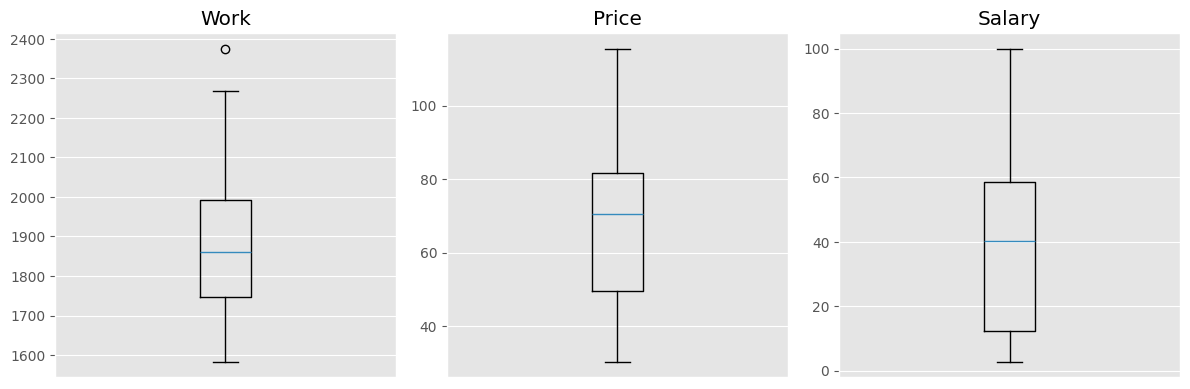

In [5]:
cols = ["Work", "Price", "Salary"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col in zip(axes, cols):
    ax.boxplot(df_knn[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])

plt.tight_layout()
plt.show()

In [6]:
Q1 = df_knn[cols].quantile(0.25)
Q3 = df_knn[cols].quantile(0.75)
IQR = Q3 - Q1

# крайние значения по правилу 1.5 × IQR
outlier_flags = ((df_knn[cols] < Q1 - 1.5 * IQR) | (df_knn[cols] > Q3 + 1.5 * IQR))

flagged = df_knn.loc[
    outlier_flags.any(axis=1),
    ["City"] + cols
].copy()

# по каким признакам выделился город
flagged["Flagged_features"] = outlier_flags.loc[flagged.index].apply(lambda row: ", ".join(row.index[row]),axis=1)

display(flagged)

,City,Work,Price,Salary,Flagged_features
15,Hong_Kong,2375.0,63.8,27.8,Work


## Стандартизация

In [7]:
all_cols = ["Work", "Price", "Salary"]

df_scaled = (df_knn[all_cols] - df_knn[all_cols].mean()) / df_knn[all_cols].std(ddof=1)

# Кластеризация

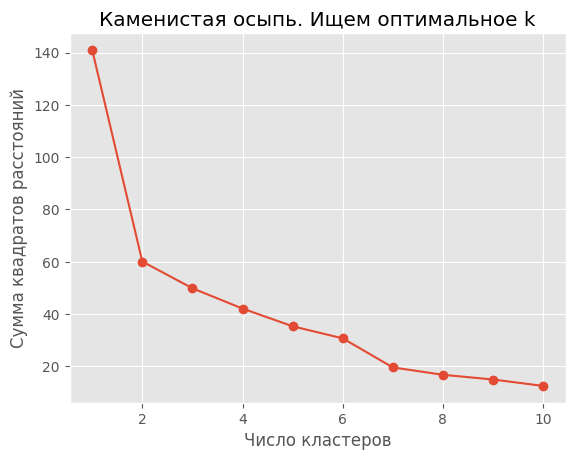

In [8]:
K = range(1, 11)

# Вычисляем значения критерия качества для разного числа кластеров
models = [KMeans(n_clusters=k, random_state=42).fit(df_scaled) for k in K]
dist = [model.inertia_ for model in models]

# Строим график каменистая осыпь
plt.plot(K, dist, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()

,k,Silhouette
0,2,0.482
1,3,0.387
2,4,0.353
3,5,0.374
4,6,0.378
5,7,0.403
6,8,0.402
7,9,0.370
8,10,0.397


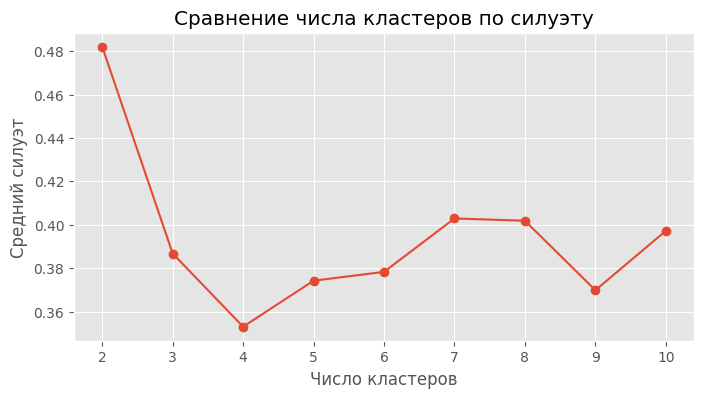

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feature_cols = ["Work", "Price", "Salary"]
X = df_scaled[feature_cols]

# Функция позволяет менять диапазон k и параметры обучения
def compare_silhouette(X, k_values, random_state=42, n_init=10):
    scores = []

    for k in k_values:
        candidate = KMeans(
            n_clusters=k,
            random_state=random_state,
            n_init=n_init,
            max_iter=300,
            tol=0.0001
        )

        labels = candidate.fit_predict(X)

        scores.append({
            "k": k,
            "Silhouette": silhouette_score(
                X, labels, metric="euclidean"
            )
        })

    return pd.DataFrame(scores)


# Тот же верхний предел, что и на твоём графике локтя
silhouette_results = compare_silhouette(X, range(2, 11))

display(silhouette_results.round(3))

plt.figure(figsize=(8, 4))
plt.plot(
    silhouette_results["k"],
    silhouette_results["Silhouette"],
    marker="o"
)
plt.xticks(silhouette_results["k"])
plt.xlabel("Число кластеров")
plt.ylabel("Средний силуэт")
plt.title("Сравнение числа кластеров по силуэту")
plt.show()

In [10]:
max_iter_1 = 300
model = KMeans(n_clusters=2, random_state=42, max_iter=max_iter_1, n_init=10,
               verbose=0, tol=0.0001 )

In [11]:
model.fit(df_scaled)

KMeans(n_clusters=2, n_init=10, random_state=42)

Самое большое снижение WCSS происходит при 2 кластерах. Так как наблюдений и самих переменных не особо много рассмотрим 2,3 и 4 кластера.

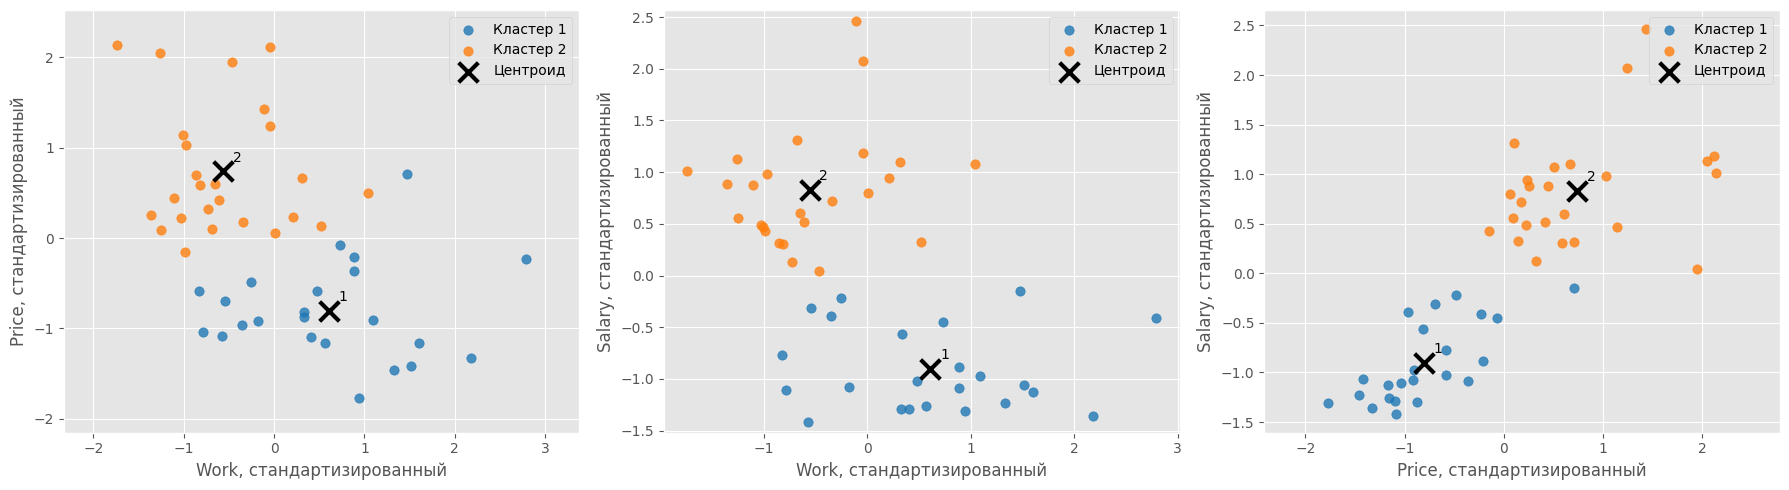

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

labels = model.labels_

# Названия и порядок признаков совпадают с данными обучения

centers = pd.DataFrame(model.cluster_centers_, columns=["Work", "Price", "Salary"])

pairs = [
    ("Work", "Price"),
    ("Work", "Salary"),
    ("Price", "Salary")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = plt.get_cmap("tab10")

for ax, (x_col, y_col) in zip(axes, pairs):
    for cluster_id in range(model.n_clusters):
        mask = labels == cluster_id

        ax.scatter(
            df_scaled.loc[mask, x_col],
            df_scaled.loc[mask, y_col],
            color=colors(cluster_id % 10),
            label=f"Кластер {cluster_id + 1}",
            s=45,
            alpha=0.8
        )

    # Центроиды обязательно чёрными крестиками
    ax.scatter(centers[x_col], centers[y_col], color="black", marker="x",
        s=200,
        linewidths=3,
        label="Центроид",
        zorder=5
    )

    for cluster_id in centers.index:
        ax.annotate(
            str(cluster_id + 1),
            (centers.loc[cluster_id, x_col],
             centers.loc[cluster_id, y_col]),
            xytext=(7, 7),
            textcoords="offset points",
            color="black"
        )

    ax.set_xlabel(f"{x_col}, стандартизированный")
    ax.set_ylabel(f"{y_col}, стандартизированный")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend()

plt.tight_layout()
plt.show()

In [13]:
import numpy as np

# Расстояния от каждого города до ВСЕХ центроидов
distances = model.transform(df_scaled)

# Для каждого города выбираем столбец его кластера
own_distances = distances[
    np.arange(len(df_scaled)),
    labels
]

result = df_knn.loc[df_scaled.index, ["City"]].copy()
result["Cluster"] = labels + 1
result["Distance_to_centroid"] = own_distances

# Показываем города, наиболее удалённые от своих центров
display(
    result.sort_values(
        "Distance_to_centroid",
        ascending=False
    )
)

mean_distance = result["Distance_to_centroid"].mean()
print(f"Среднее расстояние по всем городам: {mean_distance:.3f}")

,City,Cluster,Distance_to_centroid
15,Hong_Kong,1,2.310185
42,Taipei,1,1.900438
33,Oslo,2,1.841910
47,Zurich,2,1.828216
26,Manila,1,1.718311
23,Los_Angeles,2,1.632152
14,Helsinki,2,1.519092
44,Tokyo,2,1.515790
21,Lisbon,1,1.462733
40,Stockholm,2,1.446662


Среднее расстояние по всем городам: 1.016


In [14]:
cluster_summary = (
    result.groupby("Cluster")
    .agg(
        City_count=("City", "size"),
        Mean_distance=("Distance_to_centroid", "mean")
    )
)

display(cluster_summary.round(3))

,City_count,Mean_distance
Cluster,,
1,23,1.028
2,25,1.004


In [15]:
from sklearn.metrics import silhouette_samples

feature_cols = ["Work", "Price", "Salary"]
X = df_scaled[feature_cols]

# Силуэт каждого города по трём стандартизированным признакам
result["Silhouette"] = silhouette_samples(
    X,
    model.labels_,
    metric="euclidean"
)

# Сначала показываем города с наименьшим силуэтом
display(result.sort_values("Silhouette"))

,City,Cluster,Distance_to_centroid,Silhouette
42,Taipei,1,1.900438,0.093718
16,Houston,2,1.336122,0.110940
38,Seoul,1,1.149695,0.176477
1,Athens,1,1.301604,0.205196
21,Lisbon,1,1.462733,0.242143
23,Los_Angeles,2,1.632152,0.265350
15,Hong_Kong,1,2.310185,0.330795
43,Tel_Aviv,1,0.871875,0.354494
32,Nicosia,1,1.101935,0.355419
36,Rio_de_Janeiro,1,1.432843,0.392200


In [16]:
silhouette_by_cluster = (
    result.groupby("Cluster")
    .agg(
        City_count=("City", "size"),
        Mean_silhouette=("Silhouette", "mean")
    )
)

display(silhouette_by_cluster.round(3))

# Общее среднее по всем городам
print(f"Средний силуэт: {result['Silhouette'].mean():.3f}")

,City_count,Mean_silhouette
Cluster,,
1,23,0.466
2,25,0.496


Средний силуэт: 0.482


In [17]:
df_knn['cluster'] = model.labels_ + 1
df_knn.sort_values(by = 'cluster')

,City,Work,Price,Salary,cluster
1,Athens,1792.0,53.8,30.40,1
2,Bogota,2152.0,37.9,11.50,1
3,Bombay,2052.0,30.3,5.30,1
5,Buenos_Aires,1971.0,56.1,12.50,1
7,Caracas,2041.0,61.0,10.90,1
6,Cairo,2119.4,37.1,7.30,1
15,Hong_Kong,2375.0,63.8,27.80,1
17,Jakarta,1985.6,43.6,6.58,1
27,Mexico_City,1944.0,49.8,5.70,1
26,Manila,2268.0,40.0,4.00,1


In [18]:
df_knn.groupby("cluster")[["Work", "Price", "Salary"]].agg(["mean", "count"])

Work            Price           Salary      
                mean count       mean count       mean count
cluster                                                     
1        1993.478261    23  51.347826    23  15.529565    23
2        1789.240000    25  84.972000    25  59.032000    25

Содержательная интерпритация:

Кластер 1 - крупные города развивающихся стран, где меньше цены и зарплаты


Кластер 2 - в основном Европейские и Американские крупные города (+ Токио и Сидней), с высокими ценами и зарплатами, чуть меньшим кол.вом рабочих часов чем в городах Кластера 1

Экономически кластеризация вышла довольно логичной
